In [3]:
import h5py
import pylab as plt
import numpy as np
from matplotlib.dates import num2date
from datetime import datetime


# Load Samples Data

In [4]:
hdf_samples = h5py.File('../data/validation/bcube_samples.h5')
Bcube_samples = hdf_samples['Bcube'][:]
print(Bcube_samples.shape)
times_d2n = hdf_samples['times_d2n'][:]
hdf_samples.close()

(64, 1, 179, 360, 4, 3)


In [5]:
Bcube_samples.shape
Br_samples = Bcube_samples[:, 0, :, :, :, 0]
Br_samples.shape

(64, 179, 360, 4)

In [6]:
times_samples = num2date(times_d2n)

# Load Validation Data

In [7]:
hdf_val = h5py.File('../data/validation/bcube_valdata.h5')
Bcube_val = hdf_val['Bcube'][:]
hdf_val.close()

In [8]:
Br_val = Bcube_val[:, 0, :, :, :, 0]
Br_val.shape

(64, 179, 360, 4)

# Plot Experiment

In [9]:
sf = 1

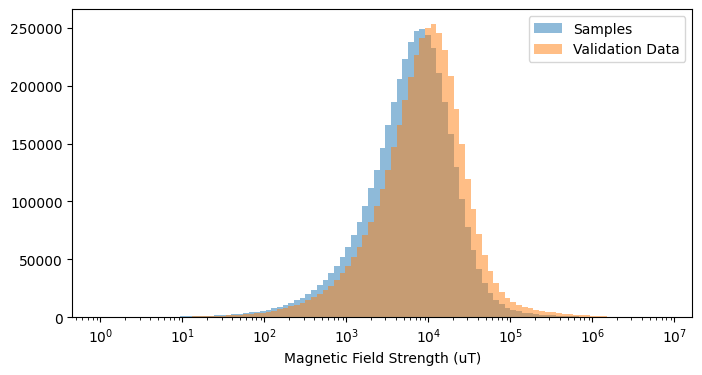

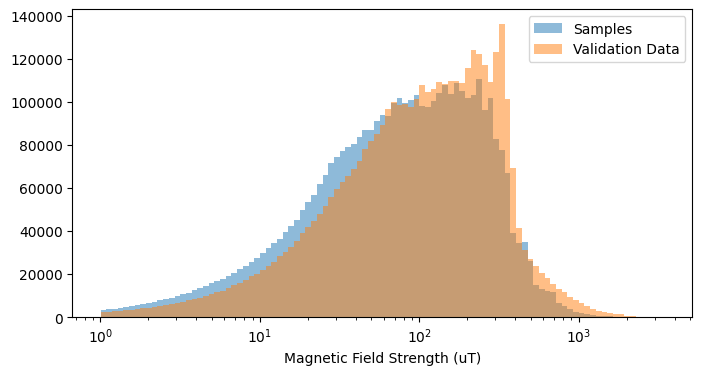

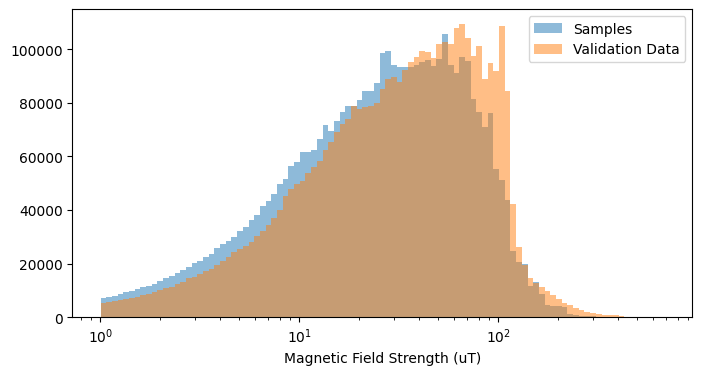

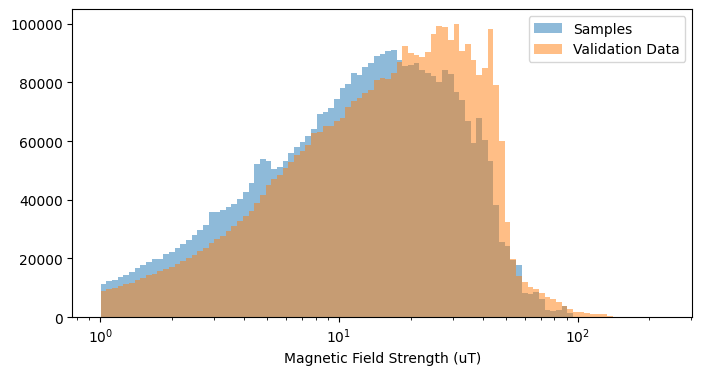

In [10]:


for i in range(4):
    L = max(np.abs(Br_samples.T[i]).max(), np.abs(Br_val.T[i]).max())
    bins = np.logspace(.001, np.log10(L), 100)
    
    plt.figure(figsize=(8, 4))
    plt.hist(np.abs(Br_samples.T[i]).flatten(), bins=bins, label='Samples', alpha=0.5)
    plt.xlabel('Magnetic Field Strength (uT)')
    plt.hist(np.abs(Br_val.T[i]).flatten(), bins=bins, label='Validation Data', alpha=0.5)
    plt.legend()
    plt.xscale('log')


In [11]:
for i in range(4):
    print('Height:', [1.0, 1.5, 2.0, 2.5][i], 'Ratio:', np.abs(Br_samples.T[i]).mean() / np.abs(Br_val.T[i]).mean())

Height: 1.0 Ratio: 0.62435865
Height: 1.5 Ratio: 0.7953326
Height: 2.0 Ratio: 0.8301074
Height: 2.5 Ratio: 0.8390362


In [12]:
1/ np.pi

0.3183098861837907

In [13]:
10**0.5

3.1622776601683795